# Milestone 15 — uncertainty and failure diagnostics

This notebook extends the team's shared metrics with conditional calibration,
tail misses, discrete-quantile diagnostics and paired SKU comparisons.
All numbers are calculated from genuine saved forecasts. The final holdout is
excluded and no training is performed. See `docs/UNCERTAINTY_ANALYSIS.md`.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'experiment.yaml').exists():
    ROOT = ROOT.parent
assert (ROOT / 'experiment.yaml').exists(), 'Run from repository root or notebooks/'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.run_uncertainty_analysis import run_analysis
from IPython.display import display, Image

tables, provenance = run_analysis()
print('Missing standard prediction files:', provenance['missing_prediction_files'])
print('Final holdout evaluated:', provenance['final_holdout_evaluated'])

Missing standard prediction files: ['deepar/predictions.parquet']
Final holdout evaluated: False


## Overall accuracy and interval quality

Point-only models have no quantiles. NA means unavailable, not zero.
Compare pinball and width alongside coverage; wider intervals alone can raise coverage.

In [2]:
display(tables['overall'][['model', 'n_observed', 'n_intervals', 'mae', 'pinball_q10', 'pinball_q50', 'pinball_q90', 'coverage_80', 'mean_interval_width_80', 'lower_miss_rate', 'upper_miss_rate']].round(4))

,model,n_observed,n_intervals,mae,pinball_q10,pinball_q50,pinball_q90,coverage_80,mean_interval_width_80,lower_miss_rate,upper_miss_rate
0,kalman_local_level,26880,26880,1.0106,0.1315,0.5053,0.3366,0.8564,2.7936,0.0330,0.1106
1,kalman_local_level_seasonal,26880,26880,1.0007,0.1318,0.5004,0.3306,0.8572,2.7626,0.0329,0.1099
2,kalman_local_trend,26880,26880,1.0225,0.1419,0.5112,0.3371,0.8537,2.7984,0.0369,0.1094
3,kalman_local_trend_seasonal,26880,26880,1.0030,0.1347,0.5015,0.3304,0.8543,2.7643,0.0366,0.1091
4,lightgbm,26880,0,0.9227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,naive_last_value,26880,0,1.2479,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,naive_weekly_seasonal,26880,0,1.1869,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Calibration across horizons and training volume

Volume groups use only history available at the origin. They are relative
terciles within the supplied cohort. The same SKU may change group over time.

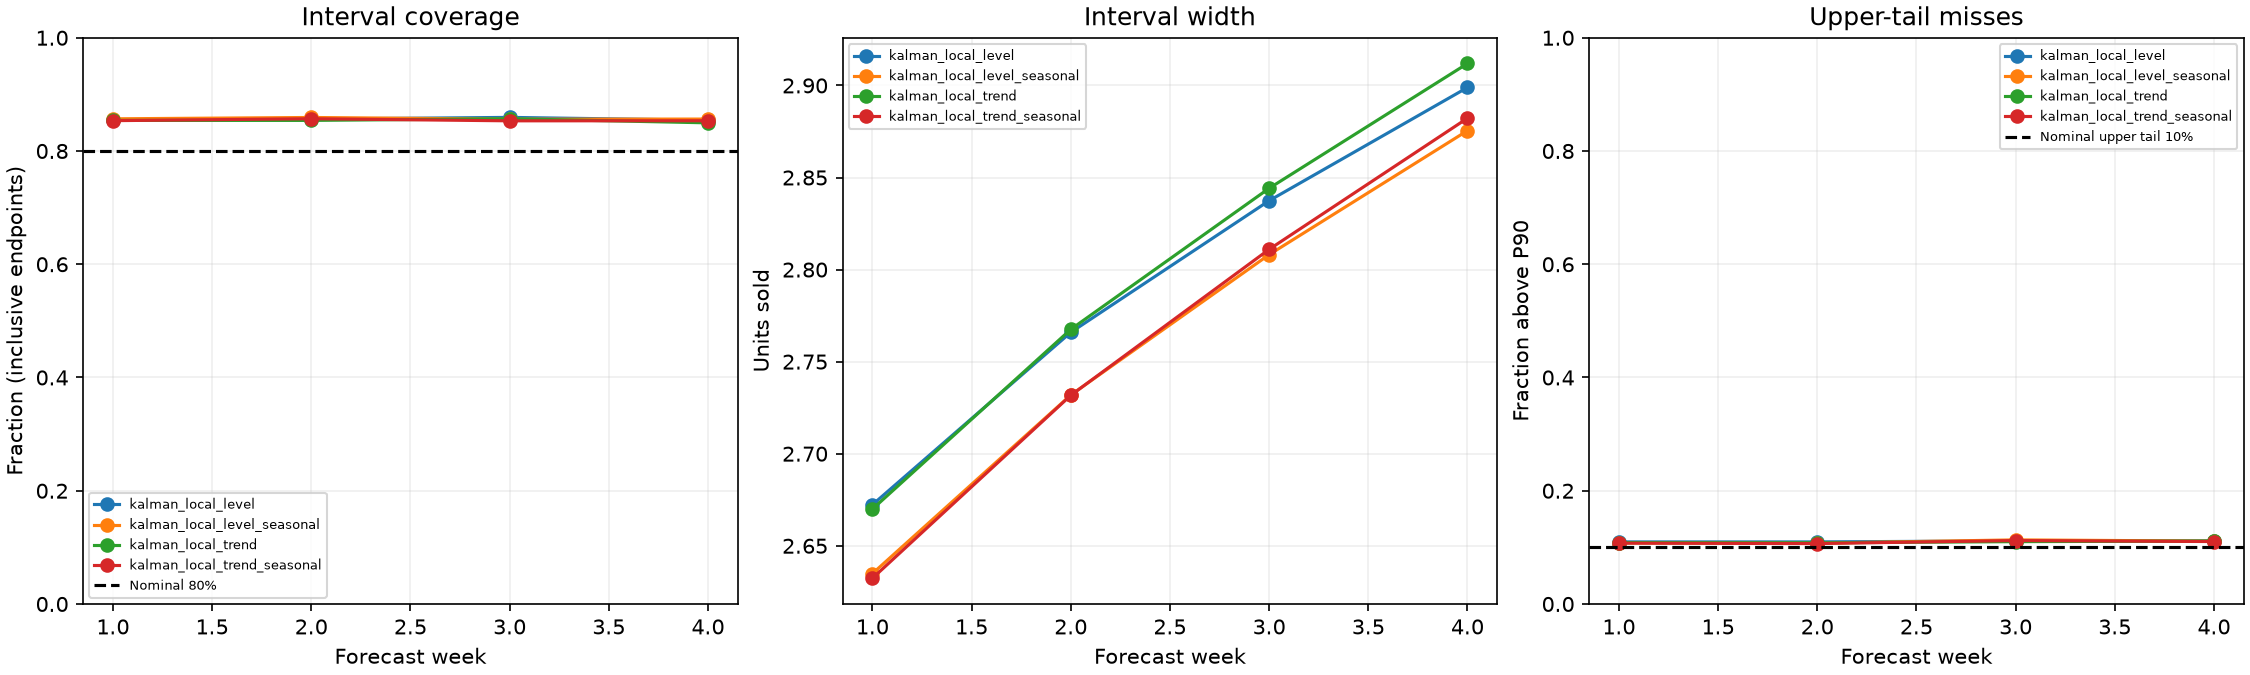

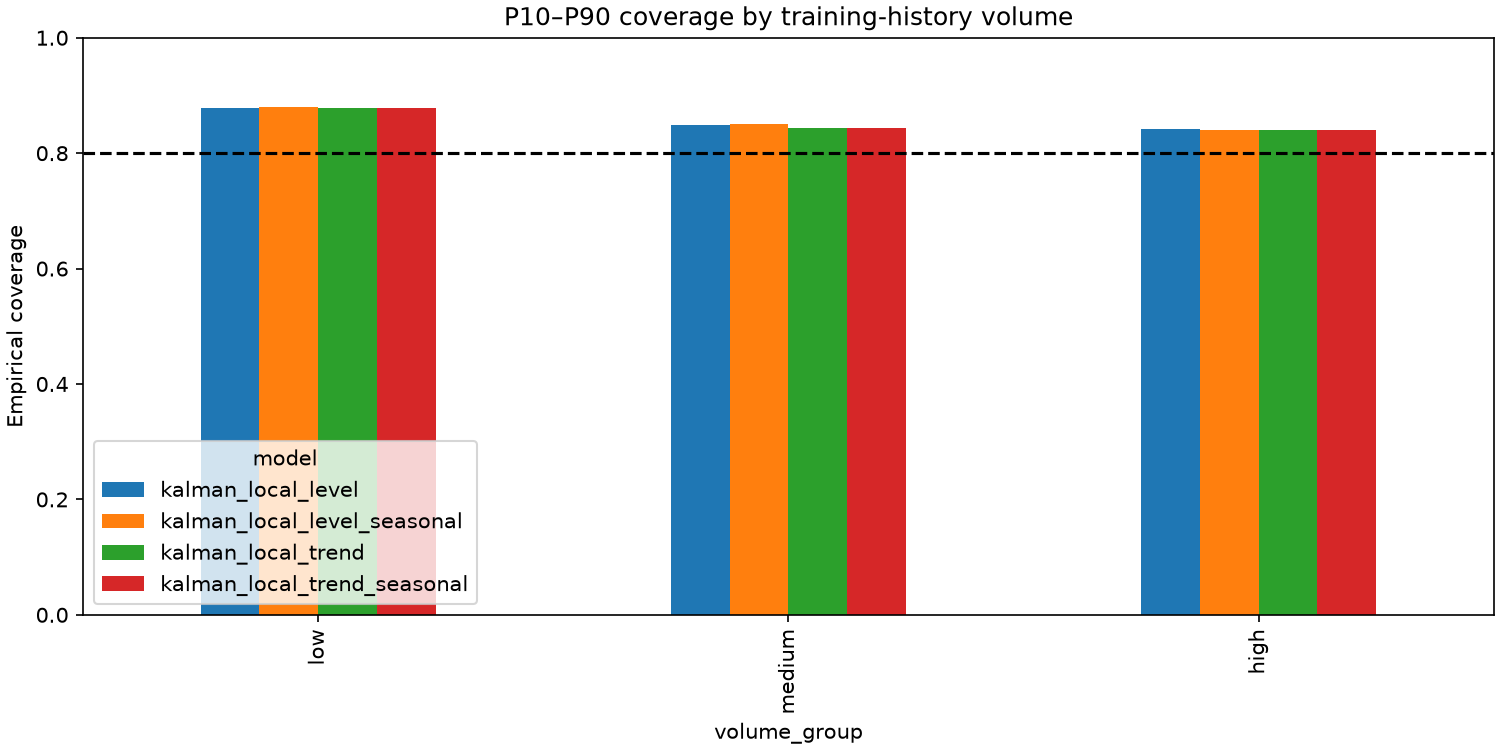

,model,volume_group,horizon_week,n_intervals,coverage_80,mean_interval_width_80
0,kalman_local_level,high,1,2240,0.8335,5.2632
1,kalman_local_level,high,2,2240,0.8464,5.5035
2,kalman_local_level,high,3,2240,0.8473,5.6828
3,kalman_local_level,high,4,2240,0.8388,5.8353
4,kalman_local_level,low,1,2240,0.8830,0.9867
...,...,...,...,...,...,...
79,naive_weekly_seasonal,low,4,0,NaN,NaN
80,naive_weekly_seasonal,medium,1,0,NaN,NaN
81,naive_weekly_seasonal,medium,2,0,NaN,NaN
82,naive_weekly_seasonal,medium,3,0,NaN,NaN


In [3]:
display(Image(filename=str(ROOT / 'reports/uncertainty_analysis/calibration_by_week.png')))
display(Image(filename=str(ROOT / 'reports/uncertainty_analysis/coverage_by_volume.png')))
display(tables['by_volume_week'][['model', 'volume_group', 'horizon_week', 'n_intervals', 'coverage_80', 'mean_interval_width_80']].round(4))

## Discrete demand and quantile ties

For a valid count quantile q, the target probability can lie between the
fractions with actual strictly below q and actual at or below q. In particular,
zero-heavy sales can make inclusive interval coverage exceed 80%. These
empirical bounds are descriptive and are not an independent-row hypothesis test.

In [4]:
display(tables['overall'][['model', 'q10_cdf_lt', 'q10_cdf_le', 'q50_cdf_lt', 'q50_cdf_le', 'q90_cdf_lt', 'q90_cdf_le']].round(4))

,model,q10_cdf_lt,q10_cdf_le,q50_cdf_lt,q50_cdf_le,q90_cdf_lt,q90_cdf_le
0,kalman_local_level,0.0330,0.5836,0.6968,0.6977,0.8894,0.8894
1,kalman_local_level_seasonal,0.0329,0.5845,0.6346,0.6942,0.8901,0.8901
2,kalman_local_trend,0.0369,0.5850,0.6616,0.6991,0.8906,0.8906
3,kalman_local_trend_seasonal,0.0366,0.5856,0.6288,0.6959,0.8908,0.8909
4,lightgbm,NaN,NaN,NaN,NaN,NaN,NaN
5,naive_last_value,NaN,NaN,NaN,NaN,NaN,NaN
6,naive_weekly_seasonal,NaN,NaN,NaN,NaN,NaN,NaN


## Where models fail and which model wins per SKU

All pairs share exact forecast keys and canonical actuals. Negative MAE
differences favor model A. Ties are explicit. Worst-series tables identify
candidates for inspection, not causal explanations of model errors.

In [5]:
display(tables['paired_series'].groupby(['model_a', 'model_b', 'winner']).size().rename('series_count').to_frame())
display(tables['worst_series'][['model', 'series_id', 'mae', 'coverage_80', 'upper_miss_rate']].round(4))
display(tables['history_labels'].head(10))

series_count
model_a                     model_b                     winner                                   
kalman_local_level          kalman_local_level_seasonal kalman_local_level                     99
                                                        kalman_local_level_seasonal           141
                            kalman_local_trend          kalman_local_level                    138
                                                        kalman_local_trend                    101
                                                        tie                                     1
                            kalman_local_trend_seasonal kalman_local_level                    104
                                                        kalman_local_trend_seasonal           136
                            lightgbm                    kalman_local_level                     32
                                                        lightgbm                              206
                                                        tie                                     2
                            naive_last_value            kalman_local_level                    158
                                                        naive_last_value                       80
                                                        tie                                     2
                            naive_weekly_seasonal       kalman_local_level                    166
                                                        naive_weekly_seasonal                  72
                                                        tie                                     2
kalman_local_level_seasonal kalman_local_trend          kalman_local_level_seasonal           138
                                                        kalman_local_trend                    102
                            kalman_local_trend_seasonal kalman_local_level_seasonal           131
                                                        kalman_local_trend_seasonal           109
                            lightgbm                    kalman_local_level_seasonal            43
                                                        lightgbm                              197
                            naive_last_value            kalman_local_level_seasonal           156
                                                        naive_last_value                       84
                            naive_weekly_seasonal       kalman_local_level_seasonal           166
                                                        naive_weekly_seasonal                  74
kalman_local_trend          kalman_local_trend_seasonal kalman_local_trend                     97
                                                        kalman_local_trend_seasonal           143
                            lightgbm                    kalman_local_trend                     30
                                                        lightgbm                              209
                                                        tie                                     1
                            naive_last_value            kalman_local_trend                    156
                                                        naive_last_value                       83
                                                        tie                                     1
                            naive_weekly_seasonal       kalman_local_trend                    166
                                                        naive_weekly_seasonal                  73
                                                        tie                                     1
kalman_local_trend_seasonal lightgbm                    kalman_local_trend_seasonal            41
                                                        lightgbm                              199
                            naive_last_value            kalman_loca

,model,series_id,mae,coverage_80,upper_miss_rate
0,kalman_local_level,FOODS_3_682__WI_3,7.8546,0.8839,0.1161
1,kalman_local_level,HOUSEHOLD_1_234__WI_2,6.6379,0.6696,0.1786
2,kalman_local_level,HOUSEHOLD_1_427__WI_2,4.7506,0.5714,0.1696
3,kalman_local_level,FOODS_3_760__CA_4,4.5643,0.6339,0.3036
4,kalman_local_level,HOBBIES_1_370__CA_2,4.4913,0.9375,0.0625
...,...,...,...,...,...
65,naive_weekly_seasonal,FOODS_3_351__CA_3,4.9286,NaN,NaN
66,naive_weekly_seasonal,FOODS_3_760__CA_4,4.7143,NaN,NaN
67,naive_weekly_seasonal,FOODS_3_086__CA_1,4.6518,NaN,NaN
68,naive_weekly_seasonal,HOBBIES_1_381__CA_4,4.6250,NaN,NaN


,series_id,origin,volume_group,history_mean,history_observed,history_zero_fraction,trailing_zero_days
0,FOODS_1_004__TX_2,1801,high,7.174903,1801,0.335369,0
28,FOODS_1_019__WI_1,1801,high,3.516935,1801,0.275958,0
56,FOODS_1_026__CA_2,1801,high,0.764575,1801,0.573015,57
84,FOODS_1_038__WI_2,1801,medium,0.369239,1801,0.734037,0
112,FOODS_1_056__WI_2,1801,low,0.145475,1801,0.898390,74
140,FOODS_1_076__CA_4,1801,medium,0.730705,1801,0.554137,27
168,FOODS_1_102__CA_4,1801,medium,0.421433,1801,0.705719,300
196,FOODS_1_105__TX_3,1801,medium,0.362021,1801,0.785675,312
224,FOODS_1_111__TX_3,1801,low,0.025541,1801,0.976680,23
252,FOODS_1_150__WI_3,1801,medium,0.671849,1801,0.604109,0


## Limits and next experiment

Saved DeepAR forecasts are absent in this local run; there is no defensible
DeepAR-vs-Kalman calibration conclusion yet. Add the genuine complete-grid
DeepAR predictions and rerun to populate the same diagnostics and paired tables.
Training provenance must be inspected separately. Zero sales do not establish
stockouts, and these results concern observed sales rather than latent demand.
Correlated series and origins limit inference from these descriptive summaries.